In [1]:
import os
path = "/kaggle/input/competitions/h-and-m-personalized-fashion-recommendations/"
print(os.listdir(path))


['sample_submission.csv', 'articles.csv', 'transactions_train.csv', 'images', 'customers.csv']


In [2]:
import os
for root, dirs, files in os.walk("/kaggle/input"):
    print(root)
    if root.count("/") > 4:
        break





/kaggle/input
/kaggle/input/competitions
/kaggle/input/competitions/h-and-m-personalized-fashion-recommendations
/kaggle/input/competitions/h-and-m-personalized-fashion-recommendations/images


In [3]:
import pandas as pd

articles = pd.read_csv(path + "articles.csv", dtype={"article_id": str})
customers = pd.read_csv(path + "customers.csv")

print(articles.shape)
print(customers.shape)
articles.head()


(105542, 25)
(1371980, 7)


,article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,...,department_name,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc
0,0108775015,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,9,Black,...,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
1,0108775044,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,10,White,...,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
2,0108775051,108775,Strap top (1),253,Vest top,Garment Upper body,1010017,Stripe,11,Off White,...,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
3,0110065001,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,9,Black,...,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."
4,0110065002,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,10,White,...,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."


In [4]:
articles.shape and customers.shape


(1371980, 7)

In [5]:
print(articles.shape)
print(customers.shape)

(105542, 25)
(1371980, 7)


In [6]:
articles.isnull().sum()

article_id                        0
product_code                      0
prod_name                         0
product_type_no                   0
product_type_name                 0
product_group_name                0
graphical_appearance_no           0
graphical_appearance_name         0
colour_group_code                 0
colour_group_name                 0
perceived_colour_value_id         0
perceived_colour_value_name       0
perceived_colour_master_id        0
perceived_colour_master_name      0
department_no                     0
department_name                   0
index_code                        0
index_name                        0
index_group_no                    0
index_group_name                  0
section_no                        0
section_name                      0
garment_group_no                  0
garment_group_name                0
detail_desc                     416
dtype: int64

In [7]:
customers.isnull().sum()

customer_id                    0
FN                        895050
Active                    907576
club_member_status          6062
fashion_news_frequency     16011
age                        15861
postal_code                    0
dtype: int64

In [8]:
customers.head()

,customer_id,FN,Active,club_member_status,fashion_news_frequency,age,postal_code
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,NaN,NaN,ACTIVE,NONE,49.0,52043ee2162cf5aa7ee79974281641c6f11a68d276429a...
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,NaN,NaN,ACTIVE,NONE,25.0,2973abc54daa8a5f8ccfe9362140c63247c5eee03f1d93...
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,NaN,NaN,ACTIVE,NONE,24.0,64f17e6a330a85798e4998f62d0930d14db8db1c054af6...
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,NaN,NaN,ACTIVE,NONE,54.0,5d36574f52495e81f019b680c843c443bd343d5ca5b1c2...
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,1.0,1.0,ACTIVE,Regularly,52.0,25fa5ddee9aac01b35208d01736e57942317d756b32ddd...


In [9]:
print("Articles:", articles["article_id"].nunique())
print("Unique descriptions:", articles["detail_desc"].nunique())
print("Unique product codes:", articles["product_code"].nunique())

Articles: 105542
Unique descriptions: 43404
Unique product codes: 47224


In [10]:
transactions = pd.read_csv(
    path + "transactions_train.csv",
    dtype={"article_id": str, "customer_id": str},
    parse_dates=["t_dat"]
)
print(transactions.shape)
transactions.head()

(31788324, 5)


,t_dat,customer_id,article_id,price,sales_channel_id
0,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,0663713001,0.050831,2
1,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,0541518023,0.030492,2
2,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,0505221004,0.015237,2
3,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,0685687003,0.016932,2
4,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,0685687004,0.016932,2


Date range

In [11]:
print(transactions["t_dat"].min(), "to", transactions["t_dat"].max())

2018-09-20 00:00:00 to 2020-09-22 00:00:00


Purchases per customer 
only 43,404 unique descriptions for 105,542 articles, and that’s almost the same as the number of product codes (47,224). So descriptions are written per product, not per colour variant, and most colour variants share identical text. That’s solid evidence for your critical point about text vs images. Only 416 descriptions are missing (about 0.4%), which is small.the median is 9 but the mean is 23 and the maximum is 1,895, so it’s heavily skewed. A quarter of customers bought 3 items or fewer.

In [12]:
per_customer = transactions.groupby("customer_id").size()
print(per_customer.describe())
print("Median:", per_customer.median())

count    1.362281e+06
mean     2.333463e+01
std      3.924225e+01
min      1.000000e+00
25%      3.000000e+00
50%      9.000000e+00
75%      2.700000e+01
max      1.895000e+03
dtype: float64
Median: 9.0


Popularity concentration
e top 1% of articles make up 18.6% of sales. That’s why “recommend the most popular” will be a tough baseline.
70% of purchases are online.

In [13]:
per_article = transactions["article_id"].value_counts()
top_1pct = int(len(per_article) * 0.01)
share = per_article.iloc[:top_1pct].sum() / per_article.sum()
print(f"Top 1% of articles = {share:.1%} of all sales")

Top 1% of articles = 18.6% of all sales


Weekly volume The data ends on Tuesday 22 September, so the final weekly bar (64,996) only covers two days. Don’t read it as a drop in sales, and don’t use calendar weeks for your split.


t_dat
2020-07-26    296129
2020-08-02    306061
2020-08-09    309830
2020-08-16    277388
2020-08-23    244577
2020-08-30    286525
2020-09-06    266497
2020-09-13    273575
2020-09-20    231309
2020-09-27     64996
Freq: W-SUN, dtype: int64


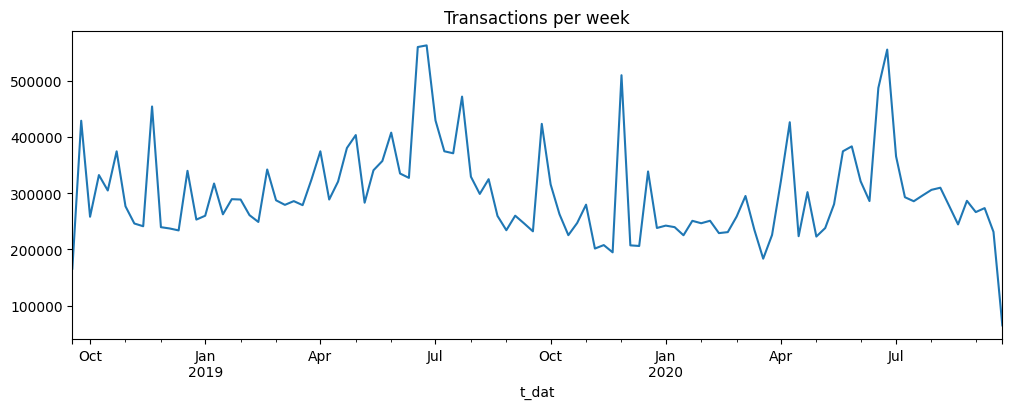

In [14]:
weekly = transactions.set_index("t_dat").resample("W").size()
weekly.plot(figsize=(12, 4), title="Transactions per week")
print(weekly.tail(10))

sales channel


In [15]:
print(transactions["sales_channel_id"].value_counts(normalize=True))

sales_channel_id
2    0.704028
1    0.295972
Name: proportion, dtype: float64


In [16]:
test_start = pd.Timestamp("2020-09-16")
train_start = test_start - pd.Timedelta(weeks=12)

In [17]:
train=transactions[(transactions["t_dat"]>= train_start) & (transactions["t_dat"]< test_start)]
test=transactions[transactions["t_dat"]>=test_start]

In [18]:
print(train["t_dat"].min(), train["t_dat"].max())
print(test["t_dat"].min(), test["t_dat"].max())

2020-06-24 00:00:00 2020-09-15 00:00:00
2020-09-16 00:00:00 2020-09-22 00:00:00


The first line counts purchases per customer. The second keeps only the customer IDs with a count of 5 or more; .index pulls out the IDs.

In [19]:
train_counts = train.groupby("customer_id").size()
active_customers = train_counts[train_counts >= 5].index
print("Active customers:", len(active_customers))

Active customers: 254444


keep customers who are in both sets. You can only evaluate someone if they were active in training and bought something in the test week:

In [20]:
eval_customers = active_customers[active_customers.isin(test["customer_id"].unique())]
train = train[train["customer_id"].isin(eval_customers)]
test = test[test["customer_id"].isin(eval_customers)]
print("Evaluation customers:", len(eval_customers))

Evaluation customers: 33168


: cold-start check. How many test purchases are of items never seen in training?

In [21]:
train_items = set(train["article_id"])
unseen = ~test["article_id"].isin(train_items)
print("Test purchases of unseen items:", unseen.sum(), f"({unseen.mean():.1%})")

Test purchases of unseen items: 8226 (6.6%)


In [22]:
for name, df in [("Train", train), ("Test", test)]:
    print(name, len(df), "rows |",
          df["customer_id"].nunique(), "customers |",
          df["article_id"].nunique(), "items")

Train 534626 rows | 33168 customers | 28593 items
Test 125341 rows | 33168 customers | 14754 items


In [23]:
train.to_parquet("/kaggle/working/train.parquet")
test.to_parquet("/kaggle/working/test.parquet")
del transactions
import gc; gc.collect()

4723